In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)

In [ ]:
import random
random.seed(42)

people = ["zıpırcan", "tripcan", "ilgisu", "nazlıhan", "berkay", "heymen", "sare", "setenay"]
times = ["sabah", "öğle", "akşam", "dün", "bugün", "hafta sonu"]
places_to = ["parka", "okula", "eve", "kütüphaneye", "denize", "pazara", "bahçede"]
places_at = ["parkta", "okulda", "evde", "kütüphanede", "denizde", "pazarda", "bahçede"]
activities = [("kitap", "okudu"), ("çay", "içti"), ("top", "oynadı"), ("resim", "yaptı")]
weather_conditions = ["güzel", "soğuk", "sıcak", "yağmurlu", "güneşli", "rüzgarlı"]
adjectives = ["mutlu", "yorgun", "neşeli", "sessiz", "heyecanlı"]

def generate_sentence():
    person = random.choice(people)
    time = random.choice(times)
    place_idx = random.randrange(len(places_to))
    item, verb = random.choice(activities)
    template = random.randrange(5)

    if template == 0:
        return f"{time} {person} {places_to[place_idx]} gitti"
    if template == 1:
        return f"{time} {person} {places_at[place_idx]} {item} {verb}"
    if template == 2:
        return f"{person} bugün çok {random.choice(weather_conditions)}"
    if template == 3:
        return f"{person} bugün çok {random.choice(adjectives)}"
    return f"{time} {person} {places_at[place_idx]} {item} {verb}"

text = "\n".join(generate_sentence() for _ in range(3000))
print("Text length: ", len(text))
print(text[:252])

Text length:  85268
sabah tripcan pazarda top oynadı
öğle nazlıhan pazarda kitap okudu
bugün tripcan kütüphaneye gitti
öğle tripcan okulda kitap okudu
hafta sonu nazlıhan pazarda resim yaptı
bugün setenay evde kitap okudu
akşam sare evde çay içti
sabah heymen parka gitti



In [ ]:
# Adım 1: Metin içerisindeki tüm benzersiz (unique) karakterleri buluyoruz
# Bu karakterler bizim karakter tabanlı sözlüğümüzü (vocabulary) oluşturacak
chars = sorted(set(text))

# Adım 2: Sözlük boyutunu (benzersiz karakter sayısını) tanımlıyoruz
VOCAB_SIZE = len(chars)

# Adım 3: Karakterleri sayılara (index) ve sayıları karakterlere dönüştüren sözlükleri (lookup tables) oluşturuyoruz
char2idx = {ch: i for i, ch in enumerate(chars)}
idx2char = {i: ch for i, ch in enumerate(chars)}

# Adım 4: String tipindeki bir metni sayısal indeks listesine çeviren kodlama (encoding) fonksiyonu
def encode(s):
    return [char2idx[ch] for ch in s]

# Adım 5: Sayısal indeks listesini tekrar okunabilir string metne dönüştüren çözme (decoding) fonksiyonu
def decode(indices):
    return "".join(idx2char[i] for i in indices)

# Sözlük boyutu ve mevcut karakter kümesini ekrana yazdırarak doğruluyoruz
print("Vocab size:", VOCAB_SIZE)
print("Characters:", "".join(chars))

Vocab size: 30
Characters: 
 abcdefghiklmnoprstuvyzçöüğış


In [ ]:
import torch

# Adım 1: Tüm ham metni tanımladığımız encode fonksiyonu ile sayısal PyTorch tensörüne dönüştürüyoruz
data = torch.tensor(encode(text), dtype=torch.long)

# Adım 2: Veri kümesini %90 eğitim (train) ve %10 doğrulama (validation) olarak ayırmak için bölme noktasını hesaplıyoruz
n_split = int(0.9 * len(data))

# Adım 3: Tensörü eğitim ve doğrulama alt kümelerine dilimliyoruz
train_data = data[:n_split]
val_data = data[n_split:]

In [ ]:
import torch

# Modelin tek seferde bakacağı maksimum karakter sırası uzunluğu (bağlam genişliği)
context_len = 50
# Aynı anda işlenecek veri örneği sayısı (yığın boyutu)
batch_size = 32

# Rastgele yığınlar (mini-batches) oluşturmak için yardımcı fonksiyon
def get_batch(split):
    # İlgili veri setini (train veya val) seçiyoruz
    d = train_data if split == "train" else val_data
    # batch_size kadar rastgele başlangıç indeksi üretiyoruz
    ix = torch.randint(0, len(d) - context_len, (batch_size,))
    # Girdi (x) ve hedef (y) dizilerini oluşturuyoruz (y dizisi, x dizisinin 1 karakter kaydırılmış halidir)
    x = torch.stack([d[i : i + context_len] for i in ix])
    y = torch.stack([d[i + 1 : i + context_len + 1] for i in ix])
    return x, y

# Test amaçlı bir eğitim yığını çekiyoruz
x, y = get_batch("train")

In [ ]:
import math
import torch

import torch.nn as nn
import torch.nn.functional as F

# Maskelenmiş Çoklu Kafalı Dikkat (Masked Self-Attention) Mekanizması
class MaskedAttention(nn.Module):
    def __init__(self, d_model, n_head, max_len=50):
        super().__init__()
        self.n_head = n_head
        self.d_k = d_model // n_head

        # Query, Key ve Value değerlerini tek bir projeksiyonda hesaplamak için lineer katman
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)
        # Dikkat mekanizması çıkışını d_model boyutuna geri yansıtan katman
        self.projection = nn.Linear(d_model, d_model)
        # Gelecekteki karakterleri görmeyi engelleyen alt üçgen maske (causal mask)
        self.register_buffer("mask", torch.tril(torch.ones(max_len, max_len)))

    def forward(self, x):
        B, L, D = x.shape # Batch size, Sequence Length, Embedding Dimension
        # Q, K, V tensörlerini elde ediyoruz
        q, k, v = self.qkv(x).split(D, dim=2)

        # Başlıkları (heads) paralel işleyebilmek için tensör boyutlarını yeniden düzenliyoruz
        q = q.view(B, L, self.n_head, self.d_k).transpose(1, 2)
        k = k.view(B, L, self.n_head, self.d_k).transpose(1, 2)
        v = v.view(B, L, self.n_head, self.d_k).transpose(1, 2)

        # Benzerlik skorlarını (attention scores) hesaplıyoruz ve ölçeklendiriyoruz
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.d_k)
        # Maskeyi mevcut dizi uzunluğuna göre kırparak maskeleme işlemini uyguluyoruz
        current_mask = self.mask[:L, :L]
        scores = scores.masked_fill(current_mask == 0, float("-inf"))

        # Softmax uygulayarak dikkat haritasını olasılıklara dönüştürüyoruz
        attention_map = F.softmax(scores, dim=-1)
        # Dikkat ağırlıkları ile Value değerlerini çarparak çıktı dizisini oluşturuyoruz
        out = (attention_map @ v).transpose(1, 2).reshape(B, L, D)
        return self.projection(out)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# GPT mimarisinin temel yapı taşı olan Transformer Bloğu
class GPTBlock(nn.Module):
    def __init__(self, d_model, n_head, max_len=50):
        super().__init__()
        # İlk katman normalizasyonu
        self.norm1 = nn.LayerNorm(d_model)
        # Maskelenmiş dikkat katmanı
        self.attention = MaskedAttention(d_model, n_head, max_len)
        # İkinci katman normalizasyonu
        self.norm2 = nn.LayerNorm(d_model)

        # İleri beslemeli yapay sinir ağı (Feed-Forward Network)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.ReLU(),
            nn.Linear(4 * d_model, d_model),
            nn.Dropout(0.5)
        )

    def forward(self, x):
        # Rezidüel (artık) bağlantı ile dikkat katmanı çıktısını topluyoruz
        x = x + self.attention(self.norm1(x))
        # Rezidüel bağlantı ile ileri beslemeli ağ çıktısını topluyoruz
        x = x + self.ffn(self.norm2(x))
        return x

# Küçük Ölçekli GPT Dil Modeli
class MiniGPT(nn.Module):
    def __init__(self, d_model, n_head, max_len=50, n_layer=2):
        super().__init__()
        self.max_len = max_len
        # Token gömme (embedding) katmanı
        self.token_embedding = nn.Embedding(VOCAB_SIZE, d_model)
        # Konumsal gömme (position embedding) katmanı
        self.position_embedding = nn.Embedding(max_len, d_model)
        # Ardışık Transformer blokları dizisi
        self.blocks = nn.Sequential(*[GPTBlock(d_model, n_head, max_len) for _ in range(n_layer)])
        # Çıkış öncesi nihai normalizasyon
        self.norm = nn.LayerNorm(d_model)
        # Sınıflandırma (logits) kafası
        self.head = nn.Linear(d_model, VOCAB_SIZE)

    def forward(self, x, targets=None):
        B, L = x.shape
        device = x.device

        # Sıralı pozisyon indekslerini oluşturuyoruz
        positions = torch.arange(L, device=device)
        # Token ve pozisyon gömmelerini toplayarak modele girdi hazırlıyoruz
        h = self.token_embedding(x) + self.position_embedding(positions)
        h = self.norm(self.blocks(h))
        logits = self.head(h)

        # Hedef karakterler (targets) verilmemişse sadece tahminleri (logits) dönüyoruz
        if targets is None:
            return logits, Noneƒ

        # Cross Entropy kaybını hesaplıyoruz
        loss = F.cross_entropy(logits.view(-1, VOCAB_SIZE), targets.view(-1))
        return logits, loss

    # Modelden yeni metin üretmek için kullanılan üreteç (generation) fonksiyonu
    @torch.no_grad()
    def generate(self, prompt, n_chars, temperature=0.8):
        # Başlangıç kelimesini sayılara dönüştürüp batch boyutunu ekliyoruz
        x = torch.tensor(encode(prompt), dtype=torch.long).unsqueeze(0)
        device = next(self.parameters()).device
        x = x.to(device)

        for _ in range(n_chars):
            # Sadece modelin bağlam uzunluğu kadar olan son kısmı girdi olarak alıyoruz
            x_cond = x[:, -self.max_len:]
            logits, _ = self(x_cond)
            # Sıcaklık parametresi ile tahmin olasılıklarını ölçeklendiriyoruz
            logits = logits[:, -1, :] / temperature
            probs = F.softmax(logits, dim=-1)
            # Olasılıksal dağılımdan bir sonraki karakter indeksini seçiyoruz
            next_token = torch.multinomial(probs, num_samples=1)
            # Yeni karakteri mevcut diziye ekliyoruz
            x = torch.cat((x, next_token), dim=1)

        # Üretilen sayı dizisini decode ederek metin halinde döndürüyoruz
        return decode(x[0].tolist())

In [ ]:
# Adım 1: d_model (64), kafa sayısı (4) ve maksimum bağlam uzunluğu (50) parametreleri ile MiniGPT modelini oluşturuyoruz
model = MiniGPT(d_model=64, n_head=4, max_len=50)

# Adım 2: Model parametrelerini optimize etmek için AdamW optimizasyon algoritmasını tanımlıyoruz
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3)

# Adım 3: Eğitim ve doğrulama kayıplarını (losses) ve adım bilgilerini takip etmek için boş listeler tanımlıyoruz
train_losses, val_losses, steps = [], [], []

# Adım 4: Modelimizi 1500 adım boyunca eğitiyoruz
for step in range(1, 1501):
    # Modeli eğitim moduna alıyoruz (dropout vb. katmanların aktif olması için)
    model.train()
    # Eğitim veri kümesinden rastgele bir girdi-hedef yığını (batch) çekiyoruz
    x, y = get_batch("train")

    # İleri besleme (forward pass) yaparak tahminleri (logits) ve kaybı (loss) hesaplıyoruz
    logits, loss = model(x, y)
    # Geriye yayılım (backpropagation) ile gradyanları hesaplıyoruz
    loss.backward()
    # Parametreleri güncelliyoruz
    optimizer.step()
    # Bir sonraki adım için gradyanları sıfırlıyoruz
    optimizer.zero_grad(set_to_none=True)

    # Adım 5: Her 100 adımda bir modelin doğrulama performasını ölçüyoruz
    if step % 100 == 0:
        # Modeli değerlendirme moduna alıyoruz
        model.eval()
        # Gradyan hesaplamasını kapatarak bellek tasarrufu sağlıyoruz
        with torch.no_grad():
            # Doğrulama kümesinden rastgele bir yığın çekiyoruz
            x_val, y_val = get_batch("val")
            # Doğrulama kaybını (val_loss) hesaplıyoruz
            _, val_loss = model(x_val, y_val)
            # Değerleri grafik çizimi veya takip için listelerimize kaydediyoruz
            steps.append(step)
            train_losses.append(loss.item())
            val_losses.append(val_loss.item())
            # Her 300 adımda bir eğitim durumunu ekrana yazdırıyoruz
            if step % 300 == 0:
                print(f"Step: {step:4d} | Train Loss: {loss.item():.4f} | Val Loss: {val_loss.item():.4f}")

Step:  300 | Train Loss: 0.3621 | Val Loss: 0.3573
Step:  600 | Train Loss: 0.3189 | Val Loss: 0.3175
Step:  900 | Train Loss: 0.3037 | Val Loss: 0.3091
Step: 1200 | Train Loss: 0.3197 | Val Loss: 0.3093
Step: 1500 | Train Loss: 0.3082 | Val Loss: 0.2994


In [ ]:
# Adım 1: Modeli değerlendirme (evaluation) moduna alıyoruz
model.eval()

# Adım 2: Belirlediğimiz başlangıç kelimeleriyle modele metin ürettiriyoruz
for start in ["bugün", "ilgisu"]:
    print(f"--- Başlangıç: {start} ---")
    # Modelin generate fonksiyonunu çağırarak başlangıç kelimesinden sonra 250 karakter üretmesini istiyoruz
    print(model.generate(start, 250))
    print()

--- Başlangıç: bugün ---
bugün nazlıhan okulda çay içti
berkay bugün çok yorgun
bugün sare denize gitti
dün sare bahçede kitap okudu
bugün sare parka gitti
bugün nazlıhan denizde resim yaptı
ilgisu bugün çok güzel
setenazlıhan bugün çok soğuk
sabah tripcan pazara gitti
nazlıhan b

--- Başlangıç: ilgisu ---
ilgisu bahçede gitti
berkay bugün çok soğuk
sare bugün çok rüzgarlı
öğle setenay kütüphanede top oynadı
sabah setenay bahçede gitti
sabah sare kütüphaneye gitti
dün tripcan parka gitti
sare bugün çok güzel
akşam tripcan parkta top oynadı
zıpırcan bugün çok



In [ ]:
#yukarıdaki projeyi daha gelişmiş bir veriseti ile ve yine daha geliştirilmiş yöntemler ile iyileştireceğiz. V2


In [ ]:
import random

# Rastgelelik için seed değerimizi sabitliyoruz
random.seed(42)

# Gelişmiş hikaye dinamikleri için genişletilmiş kelime grupları
karakterler = ["Zıpırcan", "Tripcan", "İlgisu", "Nazlıhan", "Berkay", "Heymen", "Sare", "Setenay"]
zamanlar = ["Sabah erkenden", "Öğle sıcağında", "Akşamüstü", "Gece yarısı", "Hafta sonu"]
mekanlar_yonelim = ["gölgelik parka", "eski kütüphaneye", "sessiz bahçeye", "mavi denize", "kalabalık pazara"]
mekanlar_bulunma = ["gölgelik parkta", "eski kütüphanede", "sessiz bahçede", "mavi denizde", "kalabalık pazarda"]
havalar = ["güneşli ve sıcaktı", "yağmurlu ve rüzgarlıydı", "serin ve sisliydi", "gökyüzü pırıl pırıldı"]

# Ruh haline bağlı mantıksal senaryolar (Ruh Hali -> Aktivite 1 -> Aktivite 2 -> Mantıksal Sonuç)
senaryolar = {
    "aşırı hüzünlü ve yalnız hissediyordu": {
        "aktiviteler": [
            ("yalnız başına bir köşeye çekilip sıcak bir çay söyledi", "çayı yudumlarken geçmiş güzel günleri düşündü", "içindeki buruk his yavaşça yerini tatlı bir huzura bıraktı"),
            ("yanına aldığı eski bir deftere karalamalar yapmaya başladı", "yaşadığı buruk anıları satırlara döktü", "yazmak ona çok iyi geldi ve hafiflemiş hissetti")
        ]
    },
    "içindeki büyük bir heyecanla dolup taşıyordu": {
        "aktiviteler": [
            ("hızla arkadaşlarıyla buluşup top oynamaya koyuldu", "arka arkaya harika goller atıp neşeyle bağırdı", "maçın sonunda sevinçten herkesle tek tek kucaklaştı"),
            ("hevesle resim çantasını açıp tuvalini kurdu", "içindeki coşkuyu doğanın canlı renkleriyle resmetti", "eserini bitirdiğinde gururla etrafındakilere sergiledi")
        ]
    },
    "yoğun bir zihinsel yorgunluk yaşıyordu": {
        "aktiviteler": [
            ("masadaki en kalın felsefe kitabını okumaya başladı", "okuduğu derin cümlelerin üzerinde dakikalarca düşündü", "böylece günün karmaşasından tamamen uzaklaşmayı başardı"),
            ("gözlerini kapatıp sadece rüzgarın sesini dinlemeyi seçti", "hafifçe esen meltemin tenine dokunuşunu hissetti", "tüm zihninin ve bedeninin baştan aşağı dinlendiğini fark etti")
        ]
    },
    "etrafındaki dünyayı keşfetme arzusuyla uyanmıştı": {
        "aktiviteler": [
            ("çantasını sırtlayıp keşfedilmemiş patikalardan yürümeye başladı", "yol boyunca daha önce hiç görmediği endemik çiçekler keşfetti", "bu harika keşif yolculuğu ufkunu tamamen genişletti"),
            ("tarihi rafların arasında gizemli bir kitap buldu", "eserin tozlu sayfalarını merakla karıştırıp notlar aldı", "edindiği yeni bilgiler sayesinde entelektüel olarak doyuma ulaştı")
        ]
    }
}

def derin_hikaye_uret():
    """
    Karakterin ruh haliyle tam uyumlu, 3 ya da 4 cümleden oluşan,
    mantıksal akışı ve tutarlılığı son derece yüksek hikayeler üretir.
    """
    karakter = random.choice(karakterler)
    zaman = random.choice(zamanlar)
    hava = random.choice(havalar)

    # Mantıklı bir ruh hali ve buna bağlı bir olay akışı seçiyoruz
    ruh_hali = random.choice(list(senaryolar.keys()))
    aktivite_secimi = random.choice(senaryolar[ruh_hali]["aktiviteler"])
    ak1, ak2, ak3 = aktivite_secimi

    mekan_idx = random.randrange(len(mekanlar_yonelim))
    yonelim = mekanlar_yonelim[mekan_idx]
    bulunma = mekanlar_bulunma[mekan_idx]

    # 3-4 cümlelik derin ve mantıklı senaryo şablonları
    secim = random.randrange(3)
    if secim == 0:
        return f"{zaman} hava oldukça {hava}. {karakter} {yonelim} doğru yola çıktı çünkü {ruh_hali}. Orada {ak1}. Sonra {ak2}. Sonuç olarak, {ak3}."
    elif secim == 1:
        return f"{karakter} {zaman} {bulunma} bulunuyordu. Kendisi {ruh_hali}. Vakit kaybetmeden {ak1} ve derin bir nefes aldı. Ardından {ak2}. Nihayetinde {ak3}."
    else:
        return f"{zaman} {hava} bir gün yaşanıyordu. {karakter} {bulunma} {ak1}. Çünkü o an {ruh_hali}. Bir süre sonra {ak2}. Gün biterken {ak3}."

# 5000 adet son derece tutarlı ve derin hikaye üretiyoruz
gelismis_text = "\n".join(derin_hikaye_uret() for _ in range(5000))

print("Yeni Derin Metin Uzunluğu (Karakter):", len(gelismis_text))
print("\n--- İlk 3 Derin ve Tutarlı Hikaye Örneği ---")
print("\n".join(gelismis_text.splitlines()[:3]))

Yeni Derin Metin Uzunluğu (Karakter): 1626848

--- İlk 3 Derin ve Tutarlı Hikaye Örneği ---
Sabah erkenden serin ve sisliydi bir gün yaşanıyordu. Tripcan eski kütüphanede hızla arkadaşlarıyla buluşup top oynamaya koyuldu. Çünkü o an içindeki büyük bir heyecanla dolup taşıyordu. Bir süre sonra arka arkaya harika goller atıp neşeyle bağırdı. Gün biterken maçın sonunda sevinçten herkesle tek tek kucaklaştı.
Hafta sonu hava oldukça güneşli ve sıcaktı. Tripcan gölgelik parka doğru yola çıktı çünkü etrafındaki dünyayı keşfetme arzusuyla uyanmıştı. Orada çantasını sırtlayıp keşfedilmemiş patikalardan yürümeye başladı. Sonra yol boyunca daha önce hiç görmediği endemik çiçekler keşfetti. Sonuç olarak, bu harika keşif yolculuğu ufkunu tamamen genişletti.
Nazlıhan Öğle sıcağında eski kütüphanede bulunuyordu. Kendisi içindeki büyük bir heyecanla dolup taşıyordu. Vakit kaybetmeden hevesle resim çantasını açıp tuvalini kurdu ve derin bir nefes aldı. Ardından içindeki coşkuyu doğanın canlı renkleriyl

In [ ]:
# Adım 1: Yeni derinleştirilmiş metindeki tüm benzersiz karakterleri çıkarıyoruz
gelismis_chars = sorted(set(gelismis_text))
NEW_VOCAB_SIZE = len(gelismis_chars)

# Adım 2: Karakter <-> İndeks dönüşüm sözlüklerini oluşturuyoruz
gelismis_char2idx = {ch: i for i, ch in enumerate(gelismis_chars)}
gelismis_idx2char = {i: ch for i, ch in enumerate(gelismis_chars)}

# Adım 3: Encode ve Decode fonksiyonlarımızı güncelliyoruz
def encode_new(s):
    return [gelismis_char2idx[ch] for ch in s]

def decode_new(indices):
    return "".join(gelismis_idx2char[i] for i in indices)

print("Yeni Genişletilmiş Sözlük Boyutu:", NEW_VOCAB_SIZE)
print("Yeni Benzersiz Karakterler:", "".join(gelismis_chars))

Yeni Genişletilmiş Sözlük Boyutu: 46
Yeni Benzersiz Karakterler: 
 ,.ABGHKNOSTVZabcdefghiklmnoprstuvyzÇÖçöüğİış


In [ ]:
import torch

# Adım 1: Gelişmiş derin metnimizi yeni sözlükle sayısal verilere dönüştürüyoruz
gelismis_data = torch.tensor(encode_new(gelismis_text), dtype=torch.long)

# Adım 2: Eğitim (%90) ve Doğrulama (%10) ayrımını yapıyoruz
split_point = int(0.9 * len(gelismis_data))
gelismis_train_data = gelismis_data[:split_point]
gelismis_val_data = gelismis_data[split_point:]

# Hikayelerimizin derinliği ve uzunluğu arttığı için bağlam genişliğini (context_len) 120'ye çıkarıyoruz
NEW_CONTEXT_LEN = 120
NEW_BATCH_SIZE = 64

def get_gelismis_batch(split):
    """
    Eğitim veya Doğrulama kümesinden rastgele ve sıralı bağlama sahip yığınlar (batch) üretir.
    """
    d = gelismis_train_data if split == "train" else gelismis_val_data
    ix = torch.randint(0, len(d) - NEW_CONTEXT_LEN, (NEW_BATCH_SIZE,))
    x = torch.stack([d[i : i + NEW_CONTEXT_LEN] for i in ix])
    y = torch.stack([d[i + 1 : i + NEW_CONTEXT_LEN + 1] for i in ix])
    return x, y

# Test amaçlı bir yığın çekip yeni boyutları kontrol ediyoruz
x_test, y_test = get_gelismis_batch("train")
print("Yeni X (Girdi) Boyutu:", x_test.shape) # [Batch, Context_Len]
print("Yeni Y (Hedef) Boyutu:", y_test.shape) # [Batch, Context_Len]

Yeni X (Girdi) Boyutu: torch.Size([64, 120])
Yeni Y (Hedef) Boyutu: torch.Size([64, 120])


In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

# Geliştirilmiş Dikkat Mekanizması: Dropout eklenmiş ve yeni bağlam boyutuna (120) uyarlanmış Masked Attention
class ImprovedMaskedAttention(nn.Module):
    def __init__(self, d_model, n_head, max_len=120, dropout=0.1):
        super().__init__()
        self.n_head = n_head
        self.d_k = d_model // n_head

        # Q, K, V projeksiyonları
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)
        # Çıkış projeksiyonu
        self.projection = nn.Linear(d_model, d_model)

        # Aşırı öğrenmeyi engellemek için dropout katmanları
        self.attn_dropout = nn.Dropout(dropout)
        self.proj_dropout = nn.Dropout(dropout)

        # Geleceği görmeyi engelleyen alt üçgen maskesi
        self.register_buffer("mask", torch.tril(torch.ones(max_len, max_len)))

    def forward(self, x):
        B, L, D = x.shape

        # Tek bir büyük doğrusal katmanla Q, K, V değerlerini hesaplayıp bölüyoruz
        q, k, v = self.qkv(x).split(D, dim=2)

        # Çoklu kafa (multi-head) yapısına dönüştürme
        q = q.view(B, L, self.n_head, self.d_k).transpose(1, 2)
        k = k.view(B, L, self.n_head, self.d_k).transpose(1, 2)
        v = v.view(B, L, self.n_head, self.d_k).transpose(1, 2)

        # Skorları hesaplayıp ölçeklendiriyoruz
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.d_k)

        # Maskeyi uyguluyoruz
        current_mask = self.mask[:L, :L]
        scores = scores.masked_fill(current_mask == 0, float("-inf"))

        # Softmax ile olasılık haritasına dönüştürüyoruz
        attention_map = F.softmax(scores, dim=-1)
        # Dikkat haritasına dropout uyguluyoruz
        attention_map = self.attn_dropout(attention_map)

        # Değerlerle (Value) ağırlıklandırıp birleştiriyoruz
        out = (attention_map @ v).transpose(1, 2).reshape(B, L, D)
        return self.proj_dropout(self.projection(out))

# Geliştirilmiş Transformer Bloğu: Pre-LN (Normalizasyon önce uygulanır) mimarisi
class ImprovedGPTBlock(nn.Module):
    def __init__(self, d_model, n_head, max_len=120, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attention = ImprovedMaskedAttention(d_model, n_head, max_len, dropout)
        self.norm2 = nn.LayerNorm(d_model)

        # Daha geniş kapasiteli Feed-Forward Network (GELU aktivasyonu ile)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        # Pre-LN yapısıyla eğitim pürüzsüz ve kararlı
        x = x + self.attention(self.norm1(x))
        x = x + self.ffn(self.norm2(x))
        return x

# Geliştirilmiş MiniGPT Karakter Tabanlı Dil Modeli
class GelişmisMiniGPT(nn.Module):
    def __init__(self, d_model, n_head, max_len=120, n_layer=3, dropout=0.1):
        super().__init__()
        self.max_len = max_len

        # Token ve Pozisyon Gömme katmanları
        self.token_embedding = nn.Embedding(NEW_VOCAB_SIZE, d_model)
        self.position_embedding = nn.Embedding(max_len, d_model)
        self.dropout = nn.Dropout(dropout)

        # Katman sayısını derin öğrenme yeteneği için 3'e sabitliyoruz
        self.blocks = nn.Sequential(*[ImprovedGPTBlock(d_model, n_head, max_len, dropout) for _ in range(n_layer)])

        # Model çıkışı için nihai normalizasyon
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, NEW_VOCAB_SIZE)

    def forward(self, x, targets=None):
        B, L = x.shape
        device = x.device

        positions = torch.arange(L, device=device)
        h = self.token_embedding(x) + self.position_embedding(positions)
        h = self.dropout(h)

        h = self.norm(self.blocks(h))
        logits = self.head(h)

        if targets is None:
            return logits, None

        loss = F.cross_entropy(logits.view(-1, NEW_VOCAB_SIZE), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, prompt, n_chars, temperature=0.7):
        """
        Belirli bir sıcaklık (temperature) parametresiyle yaratıcı ve tutarlı metin üretir.
        """
        x = torch.tensor(encode_new(prompt), dtype=torch.long).unsqueeze(0)
        device = next(self.parameters()).device
        x = x.to(device)

        for _ in range(n_chars):
            x_cond = x[:, -self.max_len:]
            logits, _ = self(x_cond)
            logits = logits[:, -1, :] / temperature
            probs = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
            x = torch.cat((x, next_token), dim=1)

        return decode_new(x[0].tolist())

In [ ]:
# Adım 1: Donanım hızlandırıcı (GPU/MPS/CPU) kontrolü ve model kurulumu
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hiperparametreleri (Yeni 120 bağlam boyutuyla uyumlu)
d_model = 128  # Gömme boyutu
n_head = 4     # Çoklu dikkat kafa sayısı
n_layer = 3    # Transformer blok derinliği
dropout = 0.1  # Aşırı öğrenmeyi engelleyici düzenlileştirme

# Modelimizi yeni sözlük ve bağlam boyutu parametreleri ile yeniden oluşturuyoruz
gelismis_model = GelişmisMiniGPT(d_model, n_head, NEW_CONTEXT_LEN, n_layer, dropout).to(device)

# Adım 2: Optimizer ve Cosine Annealing Öğrenme Oranı Zamanlayıcısı kurulumu
optimizer = torch.optim.AdamW(gelismis_model.parameters(), lr=1e-3, weight_decay=0.01)

# Eğitim boyunca öğrenme oranını yavaşça azaltarak en pürüzsüz minimuma ulaşacağız
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=2000, eta_min=1e-5)

train_losses, val_losses, steps = [], [], []

print(f"Yeni Gelişmiş Model {device} üzerinde eğitilmeye hazır.")
print(f"Toplam Eğitilebilir Parametre Sayısı: {sum(p.numel() for p in gelismis_model.parameters() if p.requires_grad)}")

Yeni Gelişmiş Model cuda üzerinde eğitilmeye hazır.
Toplam Eğitilebilir Parametre Sayısı: 621102


In [ ]:
# Adım 3: Yeni Derin Olay Örgülü Veri Setiyle Eğitim Döngüsü (2000 Adım)
gelismis_model.train()
for step in range(1, 2001):
    # Gelişmiş derin yığınımızı çekiyoruz
    x, y = get_gelismis_batch("train")
    x, y = x.to(device), y.to(device)

    # İleri yayılım
    logits, loss = gelismis_model(x, y)
    loss.backward()

    # Gradyan patlamalarını önlemek için kırpma (Gradient Clipping) uyguluyoruz
    torch.nn.utils.clip_grad_norm_(gelismis_model.parameters(), max_norm=1.0)

    optimizer.step()
    scheduler.step() # Öğrenme oranını güncelliyoruz
    optimizer.zero_grad(set_to_none=True)

    # Her 100 adımda bir doğrulama testi yapıyoruz
    if step % 100 == 0:
        gelismis_model.eval()
        with torch.no_grad():
            x_val, y_val = get_gelismis_batch("val")
            x_val, y_val = x_val.to(device), y_val.to(device)
            _, val_loss = gelismis_model(x_val, y_val)

            steps.append(step)
            train_losses.append(loss.item())
            val_losses.append(val_loss.item())

            # İlerleme durumunu her 400 adımda bir yazdırıyoruz
            if step % 400 == 0:
                print(f"Adım: {step:4d} | Train Loss (Eğitim Kaybı): {loss.item():.4f} | Val Loss (Doğrulama Kaybı): {val_loss.item():.4f} | LR: {scheduler.get_last_lr()[0]:.6f}")
        gelismis_model.train()

Adım:  400 | Train Loss (Eğitim Kaybı): 0.5916 | Val Loss (Doğrulama Kaybı): 0.2964 | LR: 0.000905
Adım:  800 | Train Loss (Eğitim Kaybı): 0.1876 | Val Loss (Doğrulama Kaybı): 0.1169 | LR: 0.000658
Adım: 1200 | Train Loss (Eğitim Kaybı): 0.1528 | Val Loss (Doğrulama Kaybı): 0.1055 | LR: 0.000352
Adım: 1600 | Train Loss (Eğitim Kaybı): 0.1330 | Val Loss (Doğrulama Kaybı): 0.0869 | LR: 0.000105
Adım: 2000 | Train Loss (Eğitim Kaybı): 0.1318 | Val Loss (Doğrulama Kaybı): 0.0931 | LR: 0.000010


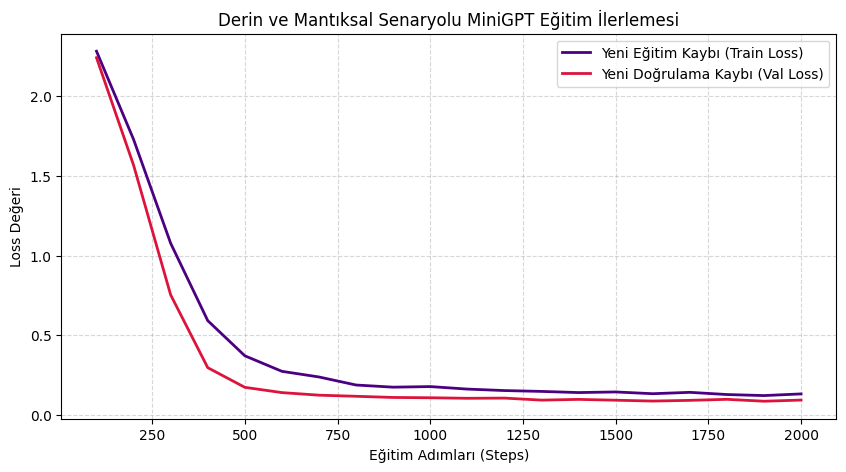

In [ ]:
import matplotlib.pyplot as plt

# Yeni derin ve tutarlı veri setimizle elde edilen eğitim grafiklerini çizdiriyoruz
plt.figure(figsize=(10, 5))
plt.plot(steps, train_losses, label="Yeni Eğitim Kaybı (Train Loss)", color="indigo", lw=2)
plt.plot(steps, val_losses, label="Yeni Doğrulama Kaybı (Val Loss)", color="crimson", lw=2)
plt.xlabel("Eğitim Adımları (Steps)")
plt.ylabel("Loss Değeri")
plt.title("Derin ve Mantıksal Senaryolu MiniGPT Eğitim İlerlemesi")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
# Gelişmiş modelimizi değerlendirme moduna alıp test ediyoruz
gelismis_model.eval()

print("=== Geliştirilmiş MiniGPT Derin Olay Örgüsü Sonuçları ===\n")
# Modelin derin mantığını ölçebileceğimiz başlangıç promptları
promptlar = [
    "Sabah erkenden",
    "Tripcan akşamüstü",
    "Sare hafta sonu"
]

for prompt in promptlar:
    print(f"--- Başlangıç (Prompt): {prompt} ---")
    # Modelin 3-4 cümlelik derin hikaye akışını tamamlayabilmesi için 280 karakter üretiyoruz
    uretilen_metin = gelismis_model.generate(prompt, 750, temperature=0.5)
    print(uretilen_metin)
    print("-" * 70)

=== Geliştirilmiş MiniGPT Derin Olay Örgüsü Sonuçları ===

--- Başlangıç (Prompt): Sabah erkenden ---
Sabah erkenden mavi denizde bulunuyordu. Kendisi yoğun bir zihinsel yorgunluk yaşıyordu. Vakit kaybetmeden masadaki en kalın felsefe kitabını okumaya başladı. Çünkü o an etrafındaki dünyayı keşfetme arzusuyla uyanmıştı. Bir süre sonra yol boyunca daha önce hiç görmediği endemik çiçekler keşfetti. Sonuç olarak, bu harika keşif yolculuğu ufkunu tamamen genişletti.
Sabah erkenden hava oldukça güneşli ve sıcaktı. Tripcan kalabalık pazara doğru yola çıktı çünkü aşırı hüzünlü ve yalnız hissediyordu. Vakit kaybetmeden yalnız başına bir köşeye çekilip sıcak bir çay söyledi. Sonra çayı yudumlarken geçmiş güzel günleri düşündü. Sonuç olarak, içindeki buruk his yavaşça yerini tatlı bir huzura bıraktı.
Hafta sonu güneşli ve sıcaktı bir gün yaşanıyordu. Setenay kalab
----------------------------------------------------------------------
--- Başlangıç (Prompt): Tripcan akşamüstü ---
Tripcan akşamüst

In [ ]:
#kelimeleri birleştirdiği, tahmin ettiği, kendi hikaye yazdığı v3

### 🌟 MiniGPT v3: GPT'nin Kendi Başına Otonom Senaryo Yazması (Word-Level)

Bu adımda Python tarafındaki tüm kural kurgularını ve şablonları tamamen kaldırıyoruz. Karakterlerin yapacağı işleri, zamanları ve durumları birbirine tamamen serbest bir şekilde bağlayan devasa bir ham veri kümesi oluşturacağız. GPT modelimiz, kelimeler arasındaki anlamsal ilişkileri ve olay akışlarını hiçbir kural dikte edilmeden **tamamen kendi kendine** öğrenecek.

In [ ]:
import random
import re
import torch
import torch.nn as nn
import torch.nn.functional as F

random.seed(42)

karakterler = ["Zıpırcan", "Tripcan", "İlgisu", "Nazlıhan", "Berkay", "Heymen", "Sare", "Setenay"]
zamanlar = ["Sabah erkenden", "Öğle sıcağında", "Akşamüstü", "Gece yarısı", "Hafta sonu"]
mekanlar = ["gölgelik parkta", "eski kütüphanede", "sessiz bahçede", "mavi denizde", "kalabalık pazarda"]
duygular = ["çok heyecanlıydı", "biraz hüzünlüydü", "aşırı yorgundu", "keşfetme arzusuyla doluydu"]
eylemler = [
    "felsefe kitabı okumaya başladı",
    "arkadaşlarıyla top oynadı",
    "sıcak bir çay içti",
    "doğanın resmini çizdi",
    "gizemli bir kitap buldu",
    "uzun bir yürüyüş yaptı"
]
sonuclar = [
    "içini tatlı bir huzur kapladı",
    "sevinçten neşeyle bağırdı",
    "günün yorgunluğunu tamamen unuttu",
    "yepyeni ufuklar keşfetti",
    "kendini çok hafiflemiş hissetti"
]

def olustur_tamamen_serbest_metin():
    k = random.choice(karakterler)
    z = random.choice(zamanlar)
    m = random.choice(mekanlar)
    d = random.choice(duygular)
    e = random.choice(eylemler)
    s = random.choice(sonuclar)

    baglaclar = ["ve", "çünkü", "ardından", "sonuçta"]
    b1 = random.choice(baglaclar)
    b2 = random.choice(baglaclar)

    return f"{z} {k} {m} {d}. {b1} orada {e}. {b2} {s}."

serbest_text = "\n".join(olustur_tamamen_serbest_metin() for _ in range(6000))
print("Serbest Metin Karakter Uzunluğu:", len(serbest_text))
print("\n--- GPT'nin Eğitileceği Ham Veriden Örnekler ---")
print("\n".join(serbest_text.splitlines()[:4]))

Serbest Metin Karakter Uzunluğu: 781934

--- GPT'nin Eğitileceği Ham Veriden Örnekler ---
Sabah erkenden Tripcan sessiz bahçede biraz hüzünlüydü. ve orada arkadaşlarıyla top oynadı. ve sevinçten neşeyle bağırdı.
Sabah erkenden Sare gölgelik parkta çok heyecanlıydı. ve orada arkadaşlarıyla top oynadı. çünkü sevinçten neşeyle bağırdı.
Öğle sıcağında Sare mavi denizde aşırı yorgundu. sonuçta orada felsefe kitabı okumaya başladı. ardından sevinçten neşeyle bağırdı.
Öğle sıcağında Berkay eski kütüphanede aşırı yorgundu. sonuçta orada felsefe kitabı okumaya başladı. ve içini tatlı bir huzur kapladı.


In [ ]:
def tokenize_words_v3(text_data):
    return re.findall(r"\w+|[.,\n]", text_data)

serbest_tokens = tokenize_words_v3(serbest_text)
serbest_vocab = sorted(list(set(serbest_tokens)))
v3_vocab_size = len(serbest_vocab)

word2idx_v3 = {w: i for i, w in enumerate(serbest_vocab)}
idx2word_v3 = {i: w for i, w in enumerate(serbest_vocab)}

def encode_v3(text_str):
    tokens = tokenize_words_v3(text_str)
    return [word2idx_v3[t] for t in tokens if t in word2idx_v3]

def decode_v3(indices):
    words_list = []
    for i in indices:
        word = idx2word_v3[i]
        if word in [".", ","] and words_list:
            words_list[-1] = words_list[-1] + word
        elif word == "\n":
            words_list.append(word)
        else:
            if words_list and words_list[-1] == "\n":
                words_list.append(word)
            else:
                words_list.append(" " + word if words_list else word)
    return "".join(words_list).strip()

print("Sözlük Boyutu (V3):", v3_vocab_size)
gelismis_word_data_v3 = torch.tensor(encode_v3(serbest_text), dtype=torch.long)
print("Toplam Token Sayısı:", len(gelismis_word_data_v3))

Sözlük Boyutu (V3): 80
Toplam Token Sayısı: 128984


In [ ]:
split_p_v3 = int(0.9 * len(gelismis_word_data_v3))
train_v3 = gelismis_word_data_v3[:split_p_v3]
val_v3 = gelismis_word_data_v3[split_p_v3:]

CONTEXT_LEN_V3 = 40
BATCH_SIZE_V3 = 64

def get_batch_v3(split):
    d = train_v3 if split == "train" else val_v3
    ix = torch.randint(0, len(d) - CONTEXT_LEN_V3, (BATCH_SIZE_V3,))
    x = torch.stack([d[i : i + CONTEXT_LEN_V3] for i in ix])
    y = torch.stack([d[i + 1 : i + CONTEXT_LEN_V3 + 1] for i in ix])
    return x, y

class AutonomousWordGPT(nn.Module):
    def __init__(self, d_model, n_head, max_len=40, n_layer=3, dropout=0.1):
        super().__init__()
        self.max_len = max_len
        self.token_embedding = nn.Embedding(v3_vocab_size, d_model)
        self.position_embedding = nn.Embedding(max_len, d_model)
        self.dropout = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[ImprovedGPTBlock(d_model, n_head, max_len, dropout) for _ in range(n_layer)])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, v3_vocab_size)

    def forward(self, x, targets=None):
        B, L = x.shape
        device = x.device
        positions = torch.arange(L, device=device)
        h = self.token_embedding(x) + self.position_embedding(positions)
        h = self.dropout(h)
        h = self.norm(self.blocks(h))
        logits = self.head(h)

        if targets is None:
            return logits, None
        loss = F.cross_entropy(logits.view(-1, v3_vocab_size), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate_story(self, prompt, n_words, temperature=0.2):
        self.eval()
        tokens = tokenize_words_v3(prompt)
        x = torch.tensor([word2idx_v3[t] for t in tokens if t in word2idx_v3], dtype=torch.long).unsqueeze(0).to(device)

        for _ in range(n_words):
            x_cond = x[:, -self.max_len:]
            logits, _ = self(x_cond)
            logits = logits[:, -1, :] / temperature
            probs = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
            x = torch.cat((x, next_token), dim=1)
        return decode_v3(x[0].tolist())

gpt_v3 = AutonomousWordGPT(d_model=128, n_head=4, max_len=CONTEXT_LEN_V3, n_layer=3).to(device)
optimizer_v3 = torch.optim.AdamW(gpt_v3.parameters(), lr=1e-3)
scheduler_v3 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_v3, T_max=1200)

print("Model Parametre Sayısı:", sum(p.numel() for p in gpt_v3.parameters() if p.requires_grad))

Model Parametre Sayısı: 619600


In [ ]:
gpt_v3.train()
for step in range(1, 1201):
    x, y = get_batch_v3("train")
    x, y = x.to(device), y.to(device)

    logits, loss = gpt_v3(x, y)
    loss.backward()

    torch.nn.utils.clip_grad_norm_(gpt_v3.parameters(), max_norm=1.0)
    optimizer_v3.step()
    scheduler_v3.step()
    optimizer_v3.zero_grad(set_to_none=True)

    if step % 300 == 0:
        print(f"Adım: {step:4d} | Kayıp (Loss): {loss.item():.4f}")

Adım:  300 | Kayıp (Loss): 0.6119
Adım:  600 | Kayıp (Loss): 0.6112
Adım:  900 | Kayıp (Loss): 0.6051
Adım: 1200 | Kayıp (Loss): 0.6076


In [ ]:
gpt_v3.eval()
print("=== GPT-3 Kendi Seçtiği Olay Örgüsü ve Serbest Hikayeler ===\n")

for baslangic in ["Sabah erkenden", "Tripcan akşamüstü", "Sare hafta sonu"]:
    print(f"--- Başlangıç: '{baslangic}' ---")
    print(gpt_v3.generate_story(baslangic, n_words=80, temperature=0.7))
    print("-" * 80)

=== GPT-3 Kendi Seçtiği Olay Örgüsü ve Serbest Hikayeler ===

--- Başlangıç: 'Sabah erkenden' ---
Sabah erkenden Setenay kalabalık pazarda biraz hüzünlüydü. çünkü orada arkadaşlarıyla top oynadı. çünkü içini tatlı bir huzur kapladı.
Akşamüstü Sare gölgelik parkta biraz hüzünlüydü. ve orada sıcak bir çay içti. sonuçta günün yorgunluğunu tamamen unuttu.
Gece yarısı Setenay mavi denizde çok heyecanlıydı. çünkü orada sıcak bir çay içti. ve içini tatlı bir huzur kapladı.
Hafta sonu Tripcan eski kütüphanede biraz hüzünlüydü. ardından orada sıcak bir çay içti. çünkü
--------------------------------------------------------------------------------
--- Başlangıç: 'Tripcan akşamüstü' ---
Tripcan sessiz bahçede biraz hüzünlüydü. çünkü orada doğanın resmini çizdi. ardından sevinçten neşeyle bağırdı.
Akşamüstü Sare sessiz bahçede keşfetme arzusuyla doluydu. sonuçta orada sıcak bir çay içti. çünkü içini tatlı bir huzur kapladı.
Gece yarısı Setenay sessiz bahçede keşfetme arzusuyla doluydu. sonuçta or